In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("Libraries imported successfully")

Libraries imported successfully


In [2]:
# Load the dataset
df = pd.read_csv("/kaggle/input/datasets/pritech/vehicle-silhouettes/vehicle.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (846, 19)


,compactness,circularity,distance_circularity,radius_ratio,pr.axis_aspect_ratio,max.length_aspect_ratio,scatter_ratio,elongatedness,pr.axis_rectangularity,max.length_rectangularity,scaled_variance,scaled_variance.1,scaled_radius_of_gyration,scaled_radius_of_gyration.1,skewness_about,skewness_about.1,skewness_about.2,hollows_ratio,class
0,95,48.0,83.0,178.0,72.0,10,162.0,42.0,20.0,159,176.0,379.0,184.0,70.0,6.0,16.0,187.0,197,van
1,91,41.0,84.0,141.0,57.0,9,149.0,45.0,19.0,143,170.0,330.0,158.0,72.0,9.0,14.0,189.0,199,van
2,104,50.0,106.0,209.0,66.0,10,207.0,32.0,23.0,158,223.0,635.0,220.0,73.0,14.0,9.0,188.0,196,car
3,93,41.0,82.0,159.0,63.0,9,144.0,46.0,19.0,143,160.0,309.0,127.0,63.0,6.0,10.0,199.0,207,van
4,85,44.0,70.0,205.0,103.0,52,149.0,45.0,19.0,144,241.0,325.0,188.0,127.0,9.0,11.0,180.0,183,bus


In [3]:
# Check and handle missing values

feature_columns = df.columns.drop("class")

missing_before = df[feature_columns].isnull().sum().sum()

df[feature_columns] = df[feature_columns].fillna(
    df[feature_columns].median()
)

missing_after = df[feature_columns].isnull().sum().sum()

print("Missing values before preprocessing:", missing_before)
print("Missing values after preprocessing:", missing_after)

Missing values before preprocessing: 41
Missing values after preprocessing: 0


In [4]:
# Define features and target

X = df.drop(columns=["class"])
y = df["class"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget classes:")
print(sorted(y.unique()))

print("\nNumber of classes:", y.nunique())

Features shape: (846, 18)
Target shape: (846,)

Target classes:
['bus', 'car', 'van']

Number of classes: 3


In [5]:
# Split the data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training set shape: (676, 18)
Testing set shape: (170, 18)

Training class distribution:
class
car    343
bus    174
van    159
Name: count, dtype: int64

Testing class distribution:
class
car    86
bus    44
van    40
Name: count, dtype: int64


In [6]:
# Train Random Forest with min_samples_split = 5

start_time = time.time()

rf_model = RandomForestClassifier(
    n_estimators=100,
    min_samples_split=5,
    random_state=42
)

rf_model.fit(X_train, y_train)

training_time = time.time() - start_time

print("Random Forest trained successfully.")
print("Training time:", training_time, "seconds")

Random Forest trained successfully.
Training time: 0.1930537223815918 seconds


In [7]:
# Make predictions and calculate evaluation metrics

y_pred = rf_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted")
recall = recall_score(y_test, y_pred, average="weighted")
f1 = f1_score(y_test, y_pred, average="weighted")

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-Score:", f1)

Accuracy: 0.9588235294117647
Precision: 0.9595000731216181
Recall: 0.9588235294117647
F1-Score: 0.9588441426051433


Confusion Matrix:
[[43  1  0]
 [ 2 81  3]
 [ 0  1 39]]


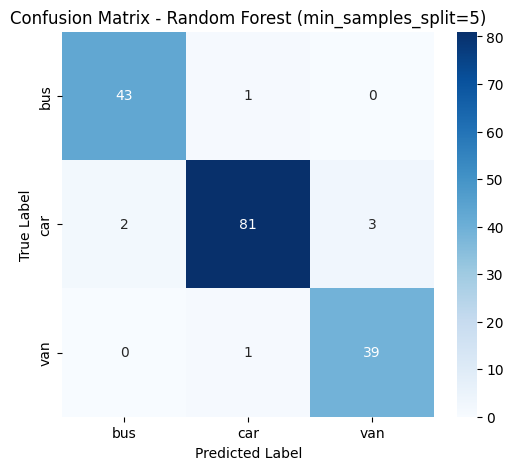

In [8]:
# Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Random Forest (min_samples_split=5)")
plt.show()

In [9]:
# Feature Importance

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

print("Feature Importance:")
display(feature_importance)

Feature Importance:


,Feature,Importance
5,max.length_aspect_ratio,0.142240
11,scaled_variance.1,0.106700
7,elongatedness,0.092190
2,distance_circularity,0.084489
9,max.length_rectangularity,0.072624
6,scatter_ratio,0.072453
10,scaled_variance,0.065692
4,pr.axis_aspect_ratio,0.059084
13,scaled_radius_of_gyration.1,0.056826
0,compactness,0.038346


In [10]:
# Results Summary

results = pd.DataFrame({
    "Model": ["Random Forest min_samples_split=5"],
    "Accuracy": [accuracy],
    "Precision": [precision],
    "Recall": [recall],
    "F1-Score": [f1],
    "Training Time": [training_time]
})

display(results)

,Model,Accuracy,Precision,Recall,F1-Score,Training Time
0,Random Forest min_samples_split=5,0.958824,0.9595,0.958824,0.958844,0.193054
